# Summary

One figure with the headline numbers and the main charts from the other notebooks. It is the picture at the top of the README.

In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

from tags import clean_tags
from viz import BAR_COLOR, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, BLUE_RAMP, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
artist_tags = clean_tags(pd.read_parquet(f'{DATA_DIR}/artist_tags.parquet'))
countries = pd.read_parquet(f'{DATA_DIR}/artist_countries.parquet')
print(df.shape, artist_tags.shape, countries.shape)

data: .
(33746, 5) (4840, 3) (1171, 2)


## Headline numbers

In [2]:
first, last = df['played_at'].min(), df['played_at'].max()

totals = {
    'scrobbles': f'{len(df):,}',
    'artists': f'{df["artist"].nunique():,}',
    'tracks': f'{len(df.drop_duplicates(["artist", "track"])):,}',
    'per day': f'{len(df) / ((last - first).days + 1):.0f}',
    'listening since': f'{first:%b %Y}',
}
totals

{'scrobbles': '33,746',
 'artists': '1,739',
 'tracks': '8,016',
 'per day': '54',
 'listening since': 'Feb 2025'}

## Data for each panel

Same calculations as the other notebooks, kept short. Months are counted as they are, so the first and current months are partial.

In [3]:
TOP_ARTISTS = 10
TOP_TAGS = 10
TOP_COUNTRIES = 10

top_artists = df['artist'].value_counts().head(TOP_ARTISTS)

local = df['played_at'].dt.tz_localize(None)  # drop the timezone, keep local wall-clock time
month = local.dt.to_period('M')
monthly = month.value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()

grid = df.groupby([df['played_at'].dt.day_of_week, df['played_at'].dt.hour]).size().unstack(fill_value=0)
grid = grid.reindex(index=range(7), columns=range(24), fill_value=0)  # rows = Monday..Sunday, columns = hour

pairs = artist_tags[['artist', 'tag']].drop_duplicates()
top_tags = df[['artist']].merge(pairs, on='artist').groupby('tag').size().nlargest(TOP_TAGS)  # a play counts once per tag

known = df[['artist']].merge(countries, on='artist').dropna(subset=['country'])
country_share = (known['country'].value_counts().head(TOP_COUNTRIES) / len(known) * 100)  # percent of plays with a country

first_month = month.groupby(df['artist']).min()  # earliest month each artist was played
new_artists = first_month.value_counts().sort_index()
new_artists = new_artists[new_artists.index > month.min()]  # every artist is new in the first month
new_artists.index = new_artists.index.to_timestamp()

Country names come from the Natural Earth file that `05_countries.ipynb` downloads. If it isn't there yet, the labels fall back to the two-letter codes.

In [4]:
WORLD_FILE = 'cache/ne_110m_admin_0_countries.geojson'
SHORT_NAMES = {'United States of America': 'United States'}

country_names = {}
if os.path.exists(WORLD_FILE):
    with open(WORLD_FILE) as f:
        for feature in json.load(f)['features']:
            props = {key.upper(): value for key, value in feature['properties'].items()}
            code = props.get('ISO_A2_EH')
            if code is None or len(code) != 2:
                code = props.get('ISO_A2')
            country_names[code] = SHORT_NAMES.get(props.get('NAME'), props.get('NAME'))

## The figure

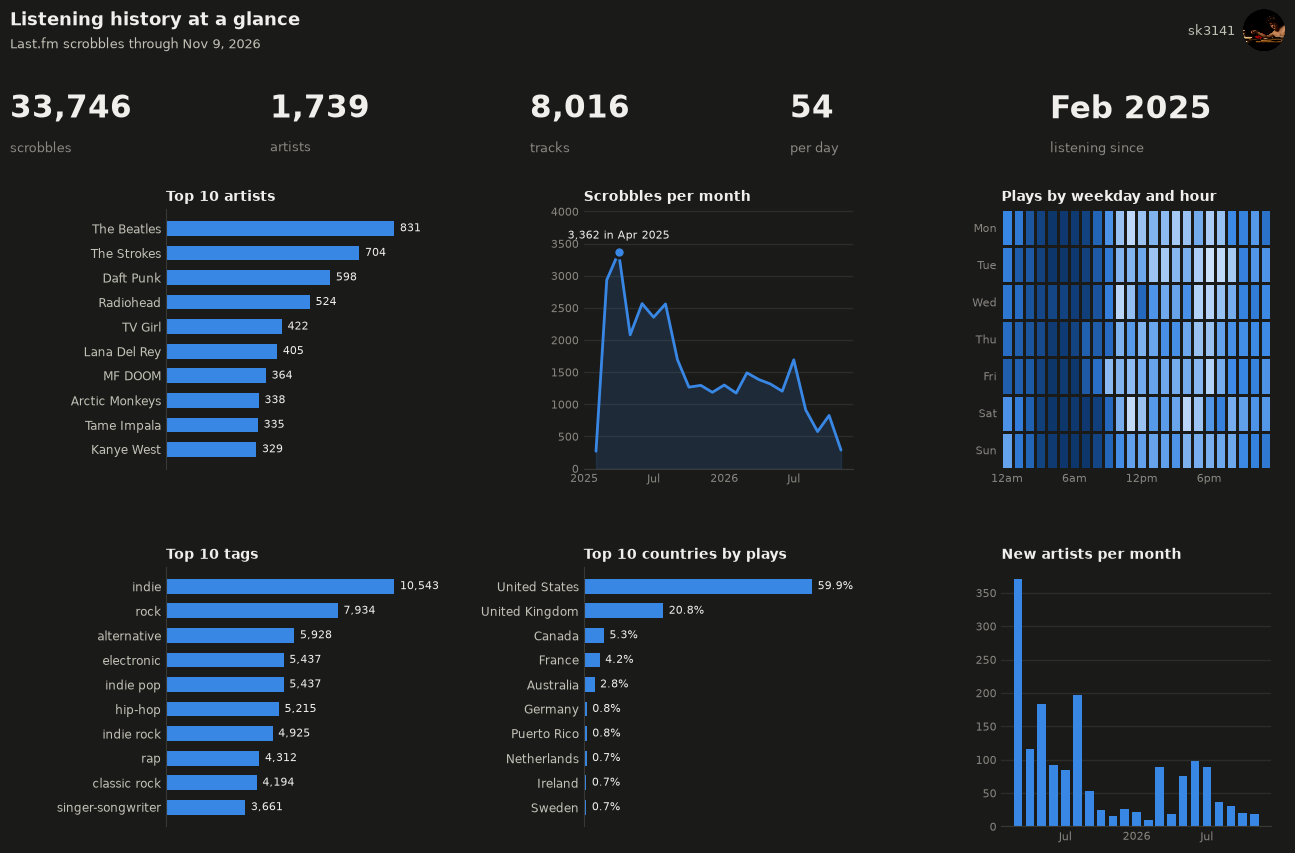

In [5]:
def shorten(text, max_chars=22):
    '''Truncate long labels so they don't squeeze the plot.'''
    return text if len(text) <= max_chars else text[:max_chars - 1].rstrip() + '…'


def style_axes(ax, title, grid_axis='y'):
    '''Panel title, hairline grid on one axis, and no frame except the baseline.'''
    ax.set_title(title, loc='left', fontsize=10, fontweight='bold', color=INK)
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=8, labelcolor=MUTED)


def ranked_bars(ax, names, values, title, label):
    '''Horizontal bars, largest on top, with the value after each bar.'''
    bars = ax.barh(names, values, height=0.6, color=BAR_COLOR)
    ax.bar_label(bars, labels=[label(v) for v in values], padding=4, fontsize=8, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, max(values) * 1.18)  # room for the value labels
    style_axes(ax, title, grid_axis='x')
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_color(BASELINE)
    ax.xaxis.set_visible(False)
    ax.tick_params(axis='y', labelsize=8.5, labelcolor=INK_SECONDARY)


def date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def plot_summary(save=False):
    '''Headline numbers on top, six panels below.'''
    width, height = 13, 8.8
    fig = plt.figure(figsize=(width, height), facecolor=SURFACE)
    panels = fig.add_gridspec(2, 3, left=0.13, right=0.98, top=1 - 2.1 / height, bottom=0.06,
                              wspace=0.55, hspace=0.38)
    axes = [fig.add_subplot(panels[row, col]) for row in range(2) for col in range(3)]
    artists_ax, monthly_ax, heat_ax, tags_ax, countries_ax, new_ax = axes

    ranked_bars(artists_ax, [shorten(name) for name in top_artists.index], top_artists.values,
                f'Top {TOP_ARTISTS} artists', lambda v: f'{v:,}')

    monthly_ax.plot(monthly.index, monthly.values, color=BAR_COLOR, linewidth=2, solid_capstyle='round')
    monthly_ax.fill_between(monthly.index, monthly.values, color=BAR_COLOR, alpha=0.15)
    peak = monthly.idxmax()
    monthly_ax.plot(peak, monthly.max(), 'o', markersize=8, color=BAR_COLOR, markeredgecolor=SURFACE, markeredgewidth=2)
    monthly_ax.annotate(f'{monthly.max():,} in {peak:%b %Y}', (peak, monthly.max()), textcoords='offset points',
                        xytext=(0, 10), ha='center', fontsize=8, color=INK)
    monthly_ax.set_ylim(0, monthly.max() * 1.2)
    style_axes(monthly_ax, 'Scrobbles per month')
    date_axis(monthly_ax)

    cmap = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)
    heat_ax.pcolormesh(grid.values, cmap=cmap, edgecolors=SURFACE, linewidth=1)
    heat_ax.set_xticks([h + 0.5 for h in (0, 6, 12, 18)], ['12am', '6am', '12pm', '6pm'])
    heat_ax.set_yticks([d + 0.5 for d in range(7)], ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
    heat_ax.invert_yaxis()  # Monday on top
    heat_ax.set_title('Plays by weekday and hour', loc='left', fontsize=10, fontweight='bold', color=INK)
    heat_ax.tick_params(length=0, labelsize=8, labelcolor=MUTED)
    for spine in heat_ax.spines.values():
        spine.set_visible(False)

    ranked_bars(tags_ax, list(top_tags.index), top_tags.values, f'Top {TOP_TAGS} tags', lambda v: f'{v:,}')

    country_labels = [country_names.get(code, code) for code in country_share.index]
    ranked_bars(countries_ax, country_labels, country_share.values,
                f'Top {TOP_COUNTRIES} countries by plays', lambda v: f'{v:.1f}%')

    new_ax.bar(new_artists.index, new_artists.values, width=22, color=BAR_COLOR)
    style_axes(new_ax, 'New artists per month')
    date_axis(new_ax)

    # headline numbers, one tile per entry
    for i, (label, value) in enumerate(totals.items()):
        x = 0.01 + i * 0.2
        fig.text(x, 1 - 0.95 / height, value, ha='left', va='top', fontsize=22, fontweight='bold', color=INK)
        fig.text(x, 1 - 1.42 / height, label, ha='left', va='top', fontsize=9, color=MUTED)

    add_title(fig, 'Listening history at a glance',
              f'Last.fm scrobbles through {last:%b} {last.day}, {last.year}', height)
    if save:
        save_figure(fig, 'summary')
    plt.show()


plot_summary(save=True)